# Does the open lane pay?

The repo's namesake question: are table signals real, do drafters act on them, and does being in the open
lane win games? Then a counterfactual in the table simulator: is it better to follow signals or to force a
colour pair? Everything here reads the JSON results, so it runs in seconds. To regenerate:

```
python scripts/open_lane.py MSH [SET ...]       # ~1 min per set
python scripts/force_vs_follow.py MSH 2000      # ~10 min; needs results/MSH.PremierDraft/picknet/models/picknet.pt
```

**Openness** of colour *j* in pack *k* is how many good cards of that colour reached the drafter later than they
usually last:

  flow[d, k, j] = Σ over picks q = 1…7, over cards c in the pack shown at q, of colour_share[c, j] × max(0, q − ALSA[c])

Picks 8+ are excluded because those packs have gone round the whole table. It is z-scored per (pack, colour)
within each draft week, so set-wide shifts in colour popularity cancel. The drafter's own picks never enter it:
it is fixed by the opened packs and the upstream drafters. A drafter's **main colours** are the top two by
playability-weighted picks. Packs pass left in P1 and P3 and right in P2, so **P1 and P3 share the upstream
neighbour**.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

# reference categorical palette, fixed order (same as results.ipynb / wheelnet.ipynb)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})

OL = {f.parent.name.split(".")[0]: json.load(open(f))
      for f in sorted((ROOT / "results").glob("*.PremierDraft/open_lane.json"))}
print(f"{len(OL)} sets: {', '.join(OL)}")

15 sets: BLB, DFT, DSK, ECL, EOE, FDN, FIN, LCI, MKM, MSH, OTJ, SOS, TDM, TLA, TMT


## 1. Are signals real?

If openness reflects the neighbour's colours rather than noise from the packs, a colour that flowed in P1 should
flow again in P3 (same neighbour) more than in P2 (the other neighbour).

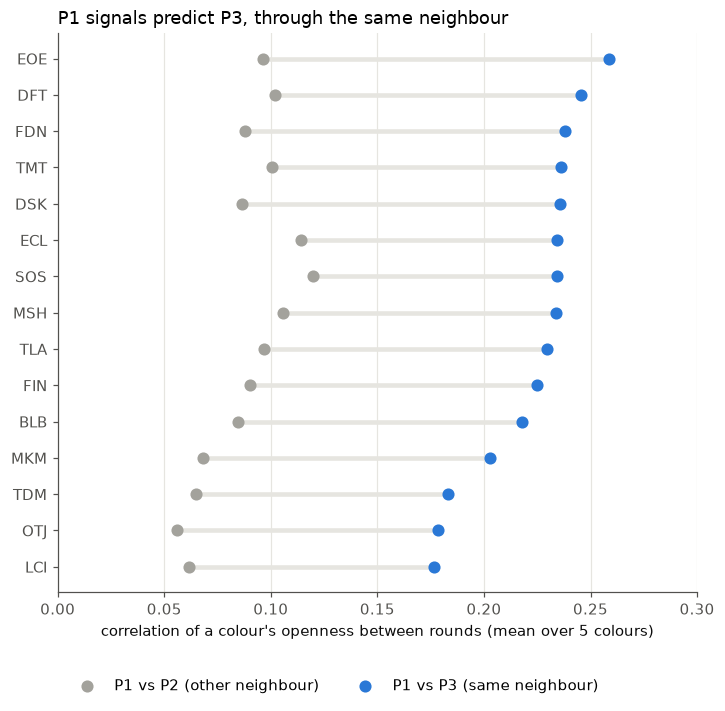

set,P1–P3 (same neighbour),P1–P2,P2–P3
str,f64,f64,f64
"""BLB""",0.217951,0.084434,0.147593
"""DFT""",0.24552,0.101883,0.13582
"""DSK""",0.235709,0.086623,0.123115
"""ECL""",0.234325,0.114189,0.155926
"""EOE""",0.258688,0.096476,0.138829
…,…,…,…
"""OTJ""",0.178597,0.055807,0.106733
"""SOS""",0.234224,0.119832,0.160642
"""TDM""",0.183213,0.064801,0.09984


In [2]:
pers = pl.DataFrame([{"set": s, "P1–P3 (same neighbour)": r["persistence"]["P1-P3 (same neighbour)"],
                      "P1–P2": r["persistence"]["P1-P2"], "P2–P3": r["persistence"]["P2-P3"]} for s, r in OL.items()]
                    ).sort("P1–P3 (same neighbour)")
fig, ax = plt.subplots(figsize=(7.5, 0.36 * pers.height + 1.2))
yy = np.arange(pers.height)
ax.hlines(yy, pers["P1–P2"], pers["P1–P3 (same neighbour)"], color=GRID, lw=3)
ax.scatter(pers["P1–P2"], yy, color=GRAY, s=48, zorder=3, label="P1 vs P2 (other neighbour)")
ax.scatter(pers["P1–P3 (same neighbour)"], yy, color=BLUE, s=48, zorder=3, label="P1 vs P3 (same neighbour)")
ax.set_yticks(yy, pers["set"]); ax.grid(axis="y", visible=False); ax.set_xlim(0, 0.3)
ax.set_xlabel("correlation of a colour's openness between rounds (mean over 5 colours)")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.13), ncol=2); ax.set_title("P1 signals predict P3, through the same neighbour", loc="left")
plt.show()
pers.sort("set")

## 2. Do drafters follow them?

Logit of "colour *j* ends up a main colour" on its P1 openness (with colour fixed effects). The slope is how much
one sd of openness moves the choice, by rank and by the 17Lands win-rate bucket.

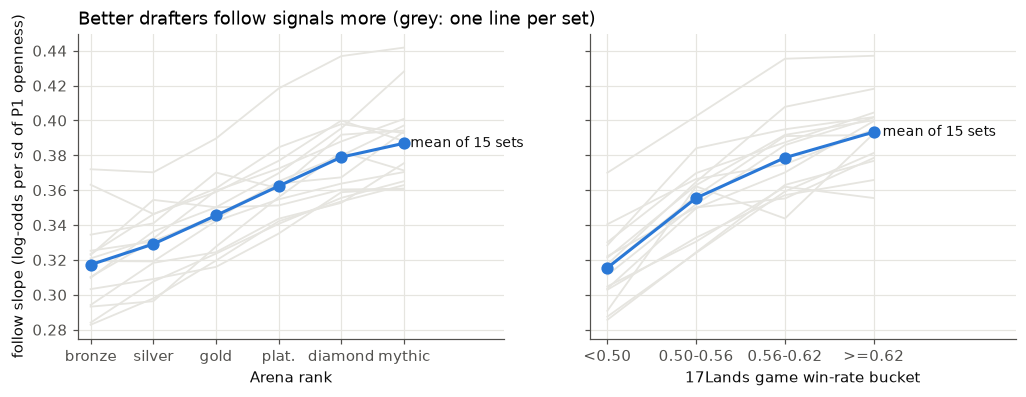

set,slope,share in most-open P1 pair
str,f64,f64
"""BLB""",0.330683,0.15845
"""DFT""",0.368767,0.167158
"""DSK""",0.374337,0.172301
"""ECL""",0.348715,0.174531
"""EOE""",0.407037,0.175776
…,…,…
"""OTJ""",0.333694,0.161255
"""SOS""",0.365205,0.20284
"""TDM""",0.346848,0.18288


In [3]:
RANKS = ["bronze", "silver", "gold", "platinum", "diamond", "mythic"]
SKILL = ["<0.50", "0.50-0.56", "0.56-0.62", ">=0.62"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, key, levels, xl in [(axes[0], "follow_by_rank", RANKS, "Arena rank"),
                            (axes[1], "follow_by_skill", SKILL, "17Lands game win-rate bucket")]:
    M = np.full((len(OL), len(levels)), np.nan)
    for i, r in enumerate(OL.values()):
        for j, lv in enumerate(levels):
            if lv in r[key]:
                M[i, j] = r[key][lv]["slope"]
        ax.plot(range(len(levels)), M[i], color=GRID, lw=1.2)
    mean = np.nanmean(M, 0)
    ax.plot(range(len(levels)), mean, color=BLUE, marker="o", ms=7)
    ax.text(len(levels) - 1 + 0.1, mean[-1], f"mean of {len(OL)} sets", color=INK, fontsize=9, va="center")
    ax.set_xticks(range(len(levels)), [lv[:4] + "." if lv == "platinum" else lv for lv in levels]); ax.set_xlim(-0.2, len(levels) + 0.6); ax.set_xlabel(xl)
axes[0].set_ylabel("follow slope (log-odds per sd of P1 openness)")
axes[0].set_title("Better drafters follow signals more (grey: one line per set)", loc="left")
plt.show()
pl.DataFrame([{"set": s, "slope": r["follow_all"]["slope"], "share in most-open P1 pair": r["share_in_most_open_P1_pair"]}
              for s, r in OL.items()])

## 3. Does it pay?

A binomial logit of the event record (p^W (1−p)^L) on the openness of the drafter's main colours, with colour-pair
fixed effects, rank and the 17Lands skill bucket. Below, game win rate by quintile of P1 openness of the main
colours (no controls), then the fitted coefficients.

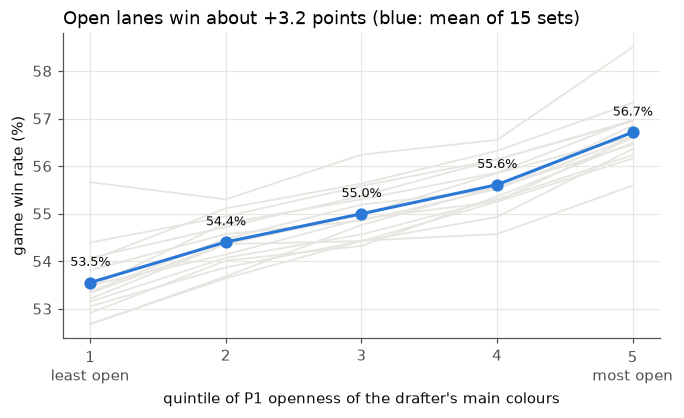

In [4]:
Q = np.array([r["winrate_by_P1_openness_quintile"] for r in OL.values() if "winrate_by_P1_openness_quintile" in r])
fig, ax = plt.subplots(figsize=(7, 3.6))
for row in Q:
    ax.plot(range(1, 6), row * 100, color=GRID, lw=1.2)
ax.plot(range(1, 6), Q.mean(0) * 100, color=BLUE, marker="o", ms=7)
for x, v in zip(range(1, 6), Q.mean(0) * 100):
    ax.text(x, v + 0.35, f"{v:.1f}%", ha="center", fontsize=8.5, color=INK)
ax.set_xticks(range(1, 6), ["1\nleast open", "2", "3", "4", "5\nmost open"])
ax.set_xlabel("quintile of P1 openness of the drafter's main colours"); ax.set_ylabel("game win rate (%)")
ax.set_title(f"Open lanes win about +{100 * (Q[:, 4] - Q[:, 0]).mean():.1f} points (blue: mean of {len(Q)} sets)", loc="left")
plt.show()

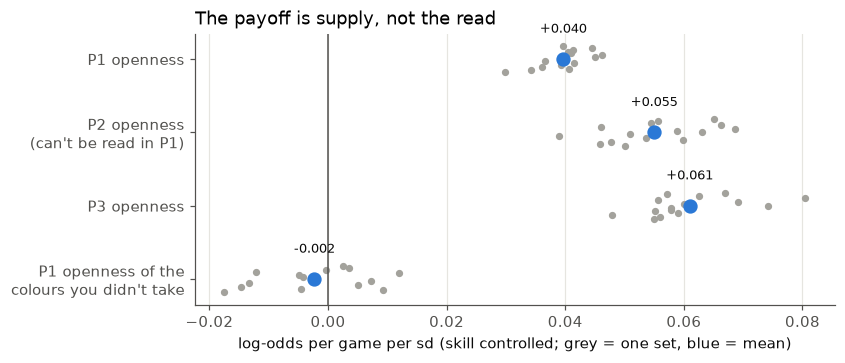

set,P1 main,± se,P1 | joint,P2 | joint,P3 | joint,main (vs other),other colours,± se other
str,f64,f64,f64,f64,f64,f64,f64,f64
"""BLB""",0.0562,0.0033,0.0397,0.0651,0.067,0.0568,0.0025,0.0054
"""DFT""",0.0604,0.0034,0.0445,0.0557,0.0572,0.061,0.0036,0.0052
"""DSK""",0.0571,0.0031,0.0413,0.0544,0.0625,0.057,-0.0004,0.0048
"""ECL""",0.065,0.0039,0.0404,0.0662,0.0805,0.0624,-0.0121,0.0062
"""EOE""",0.0557,0.0039,0.0409,0.0461,0.0556,0.0583,0.0119,0.0063
…,…,…,…,…,…,…,…,…
"""OTJ""",0.05,0.0028,0.0392,0.0536,0.0551,0.0508,0.0051,0.0042
"""SOS""",0.0566,0.0036,0.0361,0.0598,0.059,0.0528,-0.0146,0.0058
"""TDM""",0.0523,0.0037,0.0406,0.0477,0.0478,0.0517,-0.0045,0.0054


In [5]:
rows = []
for s, r in OL.items():
    p = r["payoff"]
    a = p["P1 openness of main colours | +skill"]; b = p["P1, P2, P3 separately | +skill"]
    c = p["P1 main vs P1 other colours | +skill"]
    rows.append({"set": s, "P1 main": a["coef"][0], "± se": a["se"][0],
                 "P1 | joint": b["coef"][0], "P2 | joint": b["coef"][1], "P3 | joint": b["coef"][2],
                 "main (vs other)": c["coef"][0], "other colours": c["coef"][1], "± se other": c["se"][1]})
pay = pl.DataFrame(rows)
fig, ax = plt.subplots(figsize=(7.5, 3.2))
cols = ["P1 | joint", "P2 | joint", "P3 | joint", "other colours"]
labels = ["P1 openness", "P2 openness\n(can't be read in P1)", "P3 openness", "P1 openness of the\ncolours you didn't take"]
for i, cname in enumerate(cols):
    v = pay[cname].to_numpy()
    ax.scatter(v, np.full(len(v), i) + np.linspace(-0.18, 0.18, len(v)), color=GRAY, s=14, zorder=2)
    ax.scatter([v.mean()], [i], color=BLUE, s=70, zorder=3)
    ax.text(v.mean(), i - 0.36, f"{v.mean():+.3f}", ha="center", fontsize=8.5, color=INK)
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks(range(len(cols)), labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("log-odds per game per sd (skill controlled; grey = one set, blue = mean)")
ax.set_title("The payoff is supply, not the read", loc="left")
plt.show()
pay

What this shows (all 15 sets):
1. **Signals are real and travel through your neighbour.** A colour's P1 openness correlates 0.22 with its P3
   openness and 0.09 with P2.
2. **Drafters follow, and better drafters follow more.** +1 sd of P1 openness raises the log-odds that a colour
   ends up in the deck by 0.36, rising from bronze to mythic and with the skill bucket on every set. Still, only
   ~17% end in the most open P1 pair (10% by chance).
3. **Being in the open lane wins games.** +0.055 log-odds per game per sd with skill controlled, on 15/15 sets;
   bottom to top quintile is about +3 points of game win rate.
4. **But the payoff is supply, not the read itself.** P2 openness, which you cannot read before committing, pays
   as much as P1, and openness in the colours you *didn't* take has no effect (≈ 0, negative on only 9/15 sets).
   Being where the cards are wins; this data can't separate the decision from the luck of the seat. Hence the
   counterfactual below.

## 4. Counterfactual: follow or force? (`scripts/force_vs_follow.py`)

The PickNet table simulator (`picknet.ipynb`): 2,000 tables of real opened packs, seats 1–7 always the
human-like PickNet bot, seat 0 plays a strategy. Every strategy runs on the same tables and random stream, so
differences are paired.

* **follow**: seat 0 is the human-like bot too (it reads signals as people do)
* **force**: sample from the same model, but only among cards that fit a fixed pair (colourless always fits);
  table *g* forces pair *g* mod 10
* **read 5, then lock**: free picks for P1 picks 1–5, then lock the pair that looks most open by the openness
  measure above, ignoring the cards already taken

Pools are scored as decks: for each pair, the 23 best fitting cards by training-game GIH WR (missing slots get a
10th-percentile card). The deck score is the best pair's mean.

In [6]:
FV = {f.parent.name.split(".")[0]: json.load(open(f)) for f in sorted((ROOT / "results").glob("*.PremierDraft/force_vs_follow.json"))}
rows = []
for s, r in FV.items():
    bp = r["force"]["by_pair"]; best = max(bp, key=bp.get); f = r["follow"]["seat0"]
    rows += [{"set": s, "strategy": "follow (human-like)", "deck score": 100 * f, "vs follow": 0.0, "± se": None},
             {"set": s, "strategy": "force a random pair", "deck score": 100 * r["force"]["seat0"],
              "vs follow": 100 * r["force"]["vs_follow"], "± se": 100 * r["force"]["vs_follow_se"]},
             {"set": s, "strategy": f"force the best pair ({best})", "deck score": 100 * bp[best],
              "vs follow": 100 * (bp[best] - f), "± se": None},
             {"set": s, "strategy": "read 5, then lock", "deck score": 100 * r["force_late"]["seat0"],
              "vs follow": 100 * r["force_late"]["vs_follow"], "± se": 100 * r["force_late"]["vs_follow_se"]}]
pl.DataFrame(rows)

set,strategy,deck score,vs follow,± se
str,str,f64,f64,f64
"""FDN""","""follow (human-like)""",55.781037,0.0,null
"""FDN""","""force a random pair""",55.778955,-0.002081,0.018011
"""FDN""","""force the best pair (WB)""",56.264048,0.483012,null
"""FDN""","""read 5, then lock""",55.519748,-0.261289,0.01632
"""MSH""","""follow (human-like)""",57.363874,0.0,null
"""MSH""","""force a random pair""",57.388781,0.024907,0.030321
"""MSH""","""force the best pair (WU)""",58.665085,1.301211,null
"""MSH""","""read 5, then lock""",56.941398,-0.422476,0.026574


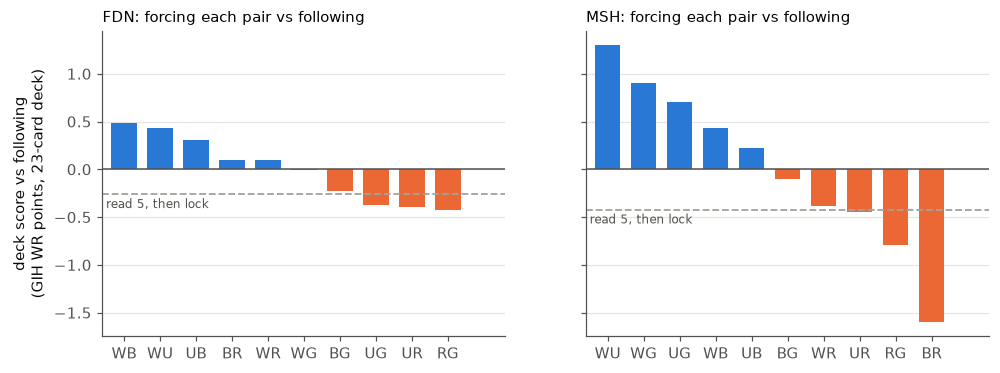

In [7]:
fig, axes = plt.subplots(1, len(FV), figsize=(5.2 * len(FV), 3.6), sharey=True, squeeze=False)
for ax, (s, r) in zip(axes[0], FV.items()):
    bp = r["force"]["by_pair"]; order = sorted(bp, key=lambda k: -bp[k])
    f = 100 * r["follow"]["seat0"]
    v = np.array([100 * bp[k] for k in order])
    ax.bar(range(10), v - f, color=[BLUE if d > 0 else ORANGE for d in v - f], width=0.7)
    ax.axhline(0, color=MUTED, lw=1)
    ax.axhline(100 * r["force_late"]["vs_follow"], color=GRAY, ls="--", lw=1.2)
    ax.text(-0.5, 100 * r["force_late"]["vs_follow"] - 0.04, "read 5, then lock", fontsize=8, color=MUTED, va="top")
    ax.set_xticks(range(10), order); ax.set_xlim(-0.6, 10.6); ax.grid(axis="x", visible=False)
    ax.set_title(f"{s}: forcing each pair vs following", loc="left", fontsize=10)
axes[0][0].set_ylabel("deck score vs following\n(GIH WR points, 23-card deck)")
plt.show()

What this shows (MSH and FDN):
1. **Forcing a random pair costs nothing** in simulation (±0.03 points): committing at P1P1 ties drafting like a
   human.
2. **Which pair matters much more than when you commit.** Forcing the strongest pair beats following (+1.3 MSH,
   +0.5 FDN), and 2.9 / 0.9 points separate the best and worst pair to force.
3. **Pure signal-chasing loses.** Locking whatever looks open after five picks, ignoring the cards already taken,
   is worst on both sets (−0.4 / −0.3). Human-style drafting balances card quality, pool and signals.

Caveats: PickNet bots under-draft MSH's best pair (WU is 17% of bot decks vs 23% of real drafters), so a WU forcer
faces less competition than at a real table. The deck score ignores curve and synergy. And every seat imitates
17Lands users, not strong drafters. A 7-forcers table, or bots that also force, would test how forcing breaks
down when others do it too.